# Prediction of Customer Churn
## Deep Nerual Network using Keras & TensorFlow
*by Zachary Porter*

In this project, a Deep Neural Network (DNN) is created to predict customer churn from a structured dataset provided by Telco.

The customer demographics are used to assist in the prediction, with the response variable being Churn_Yes (i.e., a boolean value of 1 or 0; either they churn or not)

## Libraries Used
We use the following libraries to achieve our goal:

**Numpy** -- For numeric calculations

**pandas** -- Importing data file

**matplotlib** -- To plot the training and validation data

**tensorflow** -- For creation of the deep neural network, and apply dropout and batch normalization

**sklearn** -- Building training/testing split sets, scaling, and convert categorical varaibles into numerical values

**google.colab** -- Load the drive to import data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam, SGD, RMSprop
from tensorflow.keras.models import Sequential

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

from google.colab import drive
drive.mount('/content/drive')

PATHNAME = '/content/drive/MyDrive/colab_data/'
FILENAME = 'Telco-Customer-Churn.csv'

complete_path = PATHNAME + FILENAME
loaded_data = pd.read_csv(complete_path, delim_whitespace=False, header=0)
data = loaded_data

Mounted at /content/drive


/tmp/ipykernel_11366/3518643693.py:22: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  loaded_data = pd.read_csv(complete_path, delim_whitespace=False, header=0)


In [ ]:
# Defined function to reuse plot code easily
def plot_data(history_df):
  # -------- Accuracy Plot --------
  plt.figure(figsize=(12,5))

  plt.subplot(1,2,1)
  plt.plot(history_df['accuracy'])
  plt.plot(history_df['val_accuracy'])
  plt.title('Training vs. Validation Accuracy')
  plt.xlabel('Epoch')
  plt.ylabel('Accuracy')
  plt.legend(['Train', 'Validation'])

  # -------- Loss Plot --------
  plt.subplot(1,2,2)
  plt.plot(history_df['loss'])
  plt.plot(history_df['val_loss'])
  plt.title('Training vs. Validation Loss')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.legend(['Train', 'Validation'])

  plt.show()

# Data Inspection

I will begin by checking the data types and validating that no values are missing within the dataset. The functions info() and describe() are great for collecting such information. As a result, it can be seen that no values are missing and the data types are provided.

Churn is the target variable, but it is an object data type; it needs to be converted to a Boolean or binary data type before continuing. Total charges would also be more useful as a float rather than an object. CustomerId can be removed as it is not useful for the predictions.

From the data summary provided, it also appears that the data are not normally distributed.


In [ ]:
print("\n\nData Info\n\n")
data.info()
print("-------------------------------------------------------------------------")
print("\n\nData Descriptions: \n\n")
data.describe()




Data Info


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-n

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


# Checking for and Converting Categorical Data

In this section, CustomerId is removed. Churn and TotalCharges are updated to their preferred data types for this project, and the dummy variable trap is addressed utilizing pandas. Categorical variables are converted to binary variables for proper use within the project.

In [ ]:
# Remove customer ID as it is not needed
if 'customerID' in data.columns:
  data.drop('customerID', axis=1, inplace=True)

# Change 'TotalCharges' from object type to numeric
data['TotalCharges'] = pd.to_numeric(data['TotalCharges'], errors='coerce')
data['TotalCharges'].fillna(data['TotalCharges'].mean(), inplace=True)

/tmp/ipykernel_11366/3916153800.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['TotalCharges'].fillna(data['TotalCharges'].mean(), inplace=True)


In [ ]:
# Get and display all categorical columns
cat_cols = data.select_dtypes(include=['object']).columns.tolist()
print("Categorical columns:", cat_cols)

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn']


In [ ]:
# Change categorical values to binaries
le = LabelEncoder()

binary_cols = ['gender','Partner','Dependents','PhoneService','PaperlessBilling']

for col in binary_cols:
    data[col] = le.fit_transform(data[col])

# Use pd to avoid dummy variable trap
data = pd.get_dummies(data, drop_first=True)
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Churn_Yes
0,0,0,1,0,1,0,1,29.85,29.85,True,...,False,False,False,False,False,False,False,True,False,False
1,1,0,0,0,34,1,0,56.95,1889.50,False,...,False,False,False,False,True,False,False,False,True,False
2,1,0,0,0,2,1,1,53.85,108.15,False,...,False,False,False,False,False,False,False,False,True,True
3,1,0,0,0,45,0,0,42.30,1840.75,True,...,False,False,False,False,True,False,False,False,False,False
4,0,0,0,0,2,1,1,70.70,151.65,False,...,False,False,False,False,False,False,False,True,False,True


# Data Exploration

Next, the data needs to be understood a bit more before continuing. Generating a heatmap makes correlated variables much easier to identify. As expected, if a customer does not have internet services, all related variables (streaming, device protection, etc.) are also absent. Monthly charges increase with the number of services as expected.

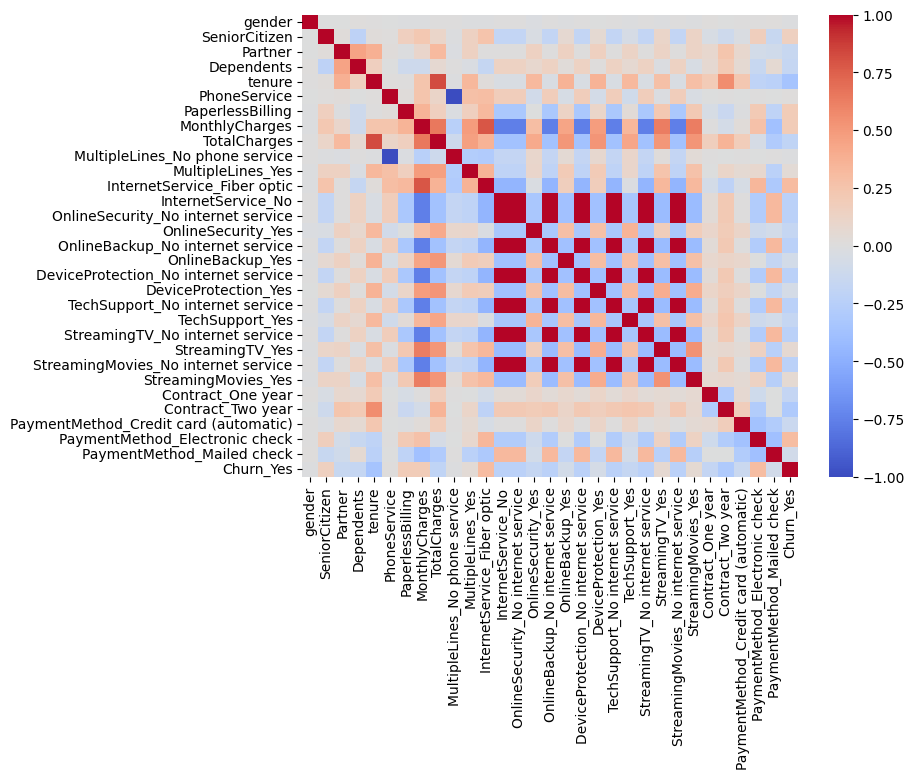

In [ ]:
plt.figure(figsize=(8,6))
sns.heatmap(data.corr(), cmap='coolwarm')
plt.show()

# Data Scaler and Splits and Feature Scaling

A model can now be constructed, splitting the data into a 20(test)/80(training) split. A scaler is applied to standardize the data set and prevent data leakage. Restricting information from training to avoid misleading results.

In [ ]:
X = data.drop('Churn_Yes', axis=1)
y = data['Churn_Yes']

X_train, X_temp, y_train, y_temp = train_test_split(X, y,
    test_size=0.5,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

# Creating DNN

This section is concerned with creating the DNN. Consisting of four layers. Dense() is used to specify the kernel size and the number of neurons per layer. For each layer, half of the previous layer’s neurons count is used for the next, continuing until the output layer, which consists of a single neuron.

Adam() implements the Adam algorithm, which helps the model determine how to update its weights. Finally, it is compiled and run. An output of the summary for the model is also generated.

In [ ]:
model = Sequential([
    # Input Layer (Hidden Layer 1)
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),

    # Hidden Layer 2
    Dense(32, activation='relu'),

    # Hidden Layer 3
    Dense(16, activation='relu'),

    # Output Layer
    Dense(1, activation='sigmoid')
])

# Optimize the Kernel
optimizer = Adam(learning_rate=0.001)

model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,609 (18.00 KB)

 Trainable params: 4,609 (18.00 KB)

 Non-trainable params: 0 (0.00 B)

# Setting History

.fit() is used to assign the variable history to record the DNN's training data. The epoch is set to 60, and a batch size of 32 per epoch. The model will train for the total of all epochs.

Afterward, the history variable is converted into a dataframe and output as a graph using plt. The results show that when training accuracy increases, validation accuracy decreases. Training loss decreases as validation loss increases; the model is clearly overfitting.

The best model will probably result from 10 to 15 epochs, and a slightly higher learning rate.

In [ ]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.7702 - loss: 0.4600 - val_accuracy: 0.7768 - val_loss: 0.4473
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8049 - loss: 0.4243 - val_accuracy: 0.7757 - val_loss: 0.4389
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8117 - loss: 0.4126 - val_accuracy: 0.7882 - val_loss: 0.4376
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8145 - loss: 0.4050 - val_accuracy: 0.7842 - val_loss: 0.4381
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8154 - loss: 0.4009 - val_accuracy: 0.7814 - val_loss: 0.4416
Epoch 6/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8179 - loss: 0.3941 - val_accuracy: 0.7876 - val_loss: 0.4373
Epoch 7/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8205 - loss: 0.3915 - val_accuracy: 0.7865 - val_loss: 0.4427
Epoch 8/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8250 - loss: 0.3851 - val_accuracy: 0.

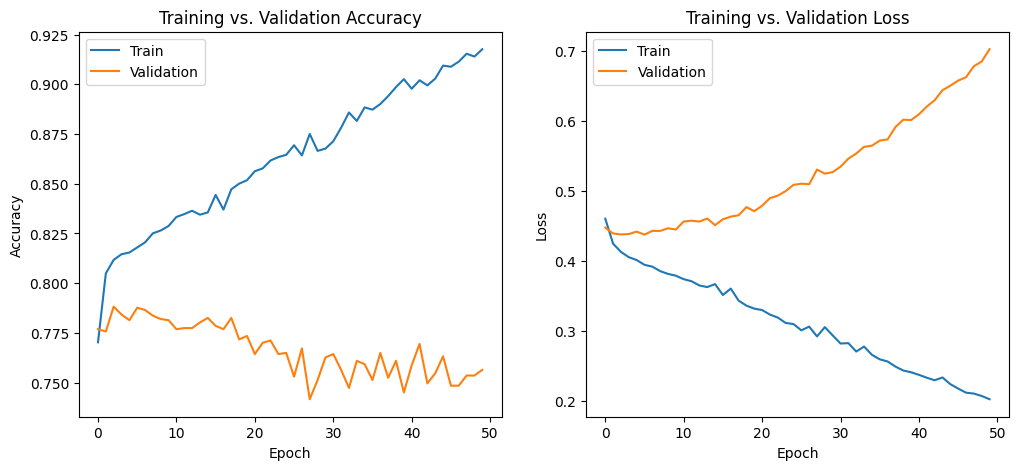

In [ ]:
history_df = pd.DataFrame(history.history)
plot_data(history_df)

# Model Evaluation

Creating a confusion matrix and a classification report is a great way to confirm whether the model is overfitting. False precision, recall, and F1-score are fine; however, the model lacks the ability to correctly identify positive cases.

Plotting training vs. validation, again, a dramatic improvement from the combination of dropout and increased learning rate (by 0.015) is seen.

In [ ]:
loss, accuracy = model.evaluate(X_val, y_val)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7564 - loss: 0.7024
Validation Loss: 0.7024
Validation Accuracy: 0.7564


In [ ]:
y_pred = (model.predict(X_test) > 0.5).astype("int32")

print("\n\n", confusion_matrix(y_test, y_pred))
print("\n\n", classification_report(y_test, y_pred))

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


 [[1066  228]
 [ 206  261]]


               precision    recall  f1-score   support

       False       0.84      0.82      0.83      1294
        True       0.53      0.56      0.55       467

    accuracy                           0.75      1761
   macro avg       0.69      0.69      0.69      1761
weighted avg       0.76      0.75      0.76      1761



# Imporvements to the Model

The model can still be improved, as always, by using dropout and an additional hidden layer. More improvement is seen with these changes; accuracy mostly hovers around ~80%, and loss around ~42% for both. Overall, the model appears more balanced for its predictions of true positives and negatives.



In [ ]:
updated_model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.35),

    Dense(32, activation='relu'),
    BatchNormalization(),

    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.35),

    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

optimizer = Adam(learning_rate=0.001)

updated_model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
history = updated_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6021 - loss: 0.6712 - val_accuracy: 0.7689 - val_loss: 0.5393
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.7464 - loss: 0.5159 - val_accuracy: 0.7751 - val_loss: 0.4751
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7697 - loss: 0.4810 - val_accuracy: 0.7808 - val_loss: 0.4520
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7714 - loss: 0.4711 - val_accuracy: 0.7899 - val_loss: 0.4440
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7859 - loss: 0.4578 - val_accuracy: 0.7888 - val_loss: 0.4427
Epoch 6/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7878 - loss: 0.4507 - val_accuracy: 0.7927 - val_loss: 0.4403
Epoch 7/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7805 - loss: 0.4569 - val_accuracy: 0.7916 - val_loss: 0.4376
Epoch 8/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7830 - loss: 0.4472 - val_accuracy: 0.

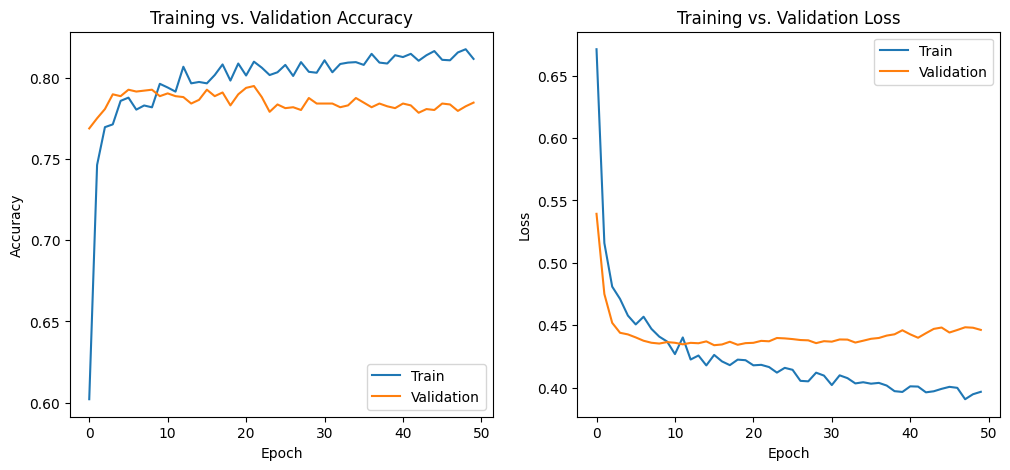

In [ ]:
history_df = pd.DataFrame(history.history)
plot_data(history_df)

In [ ]:
loss, accuracy = updated_model.evaluate(X_val, y_val)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7848 - loss: 0.4463
Validation Loss: 0.4463
Validation Accuracy: 0.7848


In [ ]:
y_pred = (updated_model.predict(X_test) > 0.5).astype("int32")

print("\n\n", confusion_matrix(y_test, y_pred))
print("\n\n", classification_report(y_test, y_pred))

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


 [[1114  180]
 [ 199  268]]


               precision    recall  f1-score   support

       False       0.85      0.86      0.85      1294
        True       0.60      0.57      0.59       467

    accuracy                           0.78      1761
   macro avg       0.72      0.72      0.72      1761
weighted avg       0.78      0.78      0.78      1761



# Switching Optimizer to SGD

Experimenting with the SGD optimizer, the model appears a better fit… visually. SGD caused the model to lose accuracy for True classes, which was the original problem. Adam is still the better choice for the model, it appears.

In [ ]:
updated_model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.35),

    Dense(32, activation='relu'),
    BatchNormalization(),

    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.35),

    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

optimizer = SGD(learning_rate=0.001)

updated_model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
sgd_history = updated_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.5391 - loss: 0.7509 - val_accuracy: 0.6530 - val_loss: 0.6538
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5655 - loss: 0.7183 - val_accuracy: 0.6729 - val_loss: 0.6316
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5970 - loss: 0.6861 - val_accuracy: 0.6831 - val_loss: 0.6125
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6297 - loss: 0.6484 - val_accuracy: 0.6934 - val_loss: 0.5972
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6487 - loss: 0.6293 - val_accuracy: 0.6990 - val_loss: 0.5819
Epoch 6/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6779 - loss: 0.6018 - val_accuracy: 0.7155 - val_loss: 0.5710
Epoch 7/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6794 - loss: 0.6123 - val_accuracy: 0.7229 - val_loss: 0.5626
Epoch 8/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6947 - loss: 0.5906 - val_accuracy: 0.

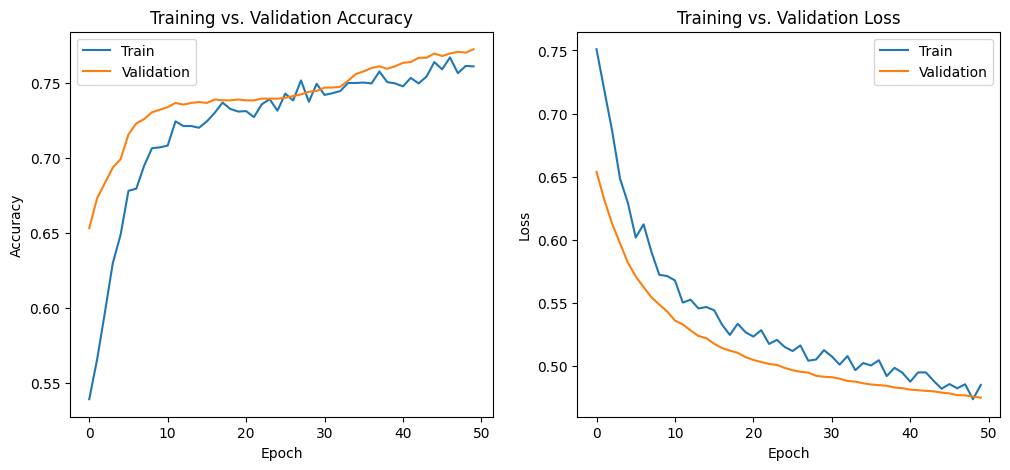

In [ ]:
sgd_history_df = pd.DataFrame(sgd_history.history)
plot_data(sgd_history_df)

In [ ]:
loss, accuracy = updated_model.evaluate(X_val, y_val)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7723 - loss: 0.4751
Validation Loss: 0.4751
Validation Accuracy: 0.7723


In [ ]:
y_pred = (updated_model.predict(X_test) > 0.5).astype("int32")

print("\n\n", confusion_matrix(y_test, y_pred))
print("\n\n", classification_report(y_test, y_pred))

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


 [[1184  110]
 [ 305  162]]


               precision    recall  f1-score   support

       False       0.80      0.91      0.85      1294
        True       0.60      0.35      0.44       467

    accuracy                           0.76      1761
   macro avg       0.70      0.63      0.64      1761
weighted avg       0.74      0.76      0.74      1761



# Switching Optimizer to RMSprop

Further optimizer experimentation. Using RMSprop, performance is similar to Adam; however, it still appears to be worse than Adam, though not by much. This is likely because the model has slightly lower recall, identifying more False Positives for the True class.

In [ ]:
updated_model = Sequential([
    Dense(64, activation='relu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.35),

    Dense(32, activation='relu'),
    BatchNormalization(),

    Dense(16, activation='relu'),
    BatchNormalization(),
    Dropout(0.35),

    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

optimizer = RMSprop(learning_rate=0.001)

updated_model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
rms_history = updated_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.5839 - loss: 0.6784 - val_accuracy: 0.7581 - val_loss: 0.5250
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7458 - loss: 0.5070 - val_accuracy: 0.7740 - val_loss: 0.4632
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7617 - loss: 0.4842 - val_accuracy: 0.7899 - val_loss: 0.4531
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7785 - loss: 0.4694 - val_accuracy: 0.7922 - val_loss: 0.4444
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7901 - loss: 0.4480 - val_accuracy: 0.7916 - val_loss: 0.4450
Epoch 6/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7952 - loss: 0.4475 - val_accuracy: 0.7882 - val_loss: 0.4425
Epoch 7/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7935 - loss: 0.4465 - val_accuracy: 0.7899 - val_loss: 0.4414
Epoch 8/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7958 - loss: 0.4346 - val_accuracy: 0.

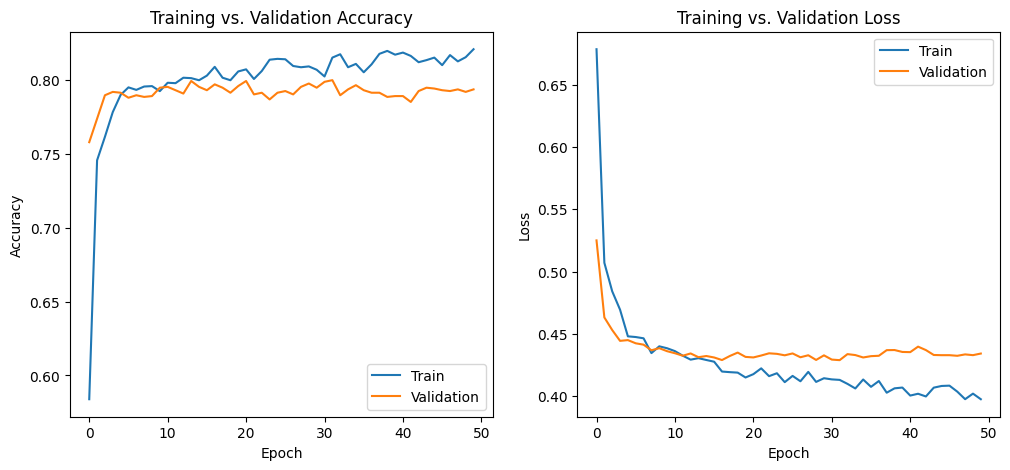

In [ ]:
rms_history_df = pd.DataFrame(rms_history.history)
plot_data(rms_history_df)

In [ ]:
loss, accuracy = updated_model.evaluate(X_val, y_val)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7939 - loss: 0.4342
Validation Loss: 0.4342
Validation Accuracy: 0.7939


In [ ]:
y_pred = (updated_model.predict(X_test) > 0.5).astype("int32")

print("\n\n", confusion_matrix(y_test, y_pred))
print("\n\n", classification_report(y_test, y_pred))

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


 [[1143  151]
 [ 206  261]]


               precision    recall  f1-score   support

       False       0.85      0.88      0.86      1294
        True       0.63      0.56      0.59       467

    accuracy                           0.80      1761
   macro avg       0.74      0.72      0.73      1761
weighted avg       0.79      0.80      0.79      1761



# Tuning Hyperparameters

Various numbers of layers, neurons, and learning rates are now being tested to determine which yields the best performance. Starting at 60 neurons and decreasing by approximately half in each layer, and a dropout ranging from 0.15 to 0.35, with the lowest layer having the least amount of dropout applied.

In [ ]:
updated_model = Sequential([
    Dense(60, activation='relu', input_dim=X_train.shape[1]),
    BatchNormalization(),
    Dropout(0.35),

    Dense(30, activation='relu'),
    BatchNormalization(),
    Dropout(0.35),

    Dense(15, activation='relu'),
    BatchNormalization(),
    Dropout(0.35),

    Dense(7, activation='relu'),
    BatchNormalization(),
    Dropout(0.25),

    Dense(4, activation='relu'),
    BatchNormalization(),
    Dropout(0.15),

    Dense(1, activation='sigmoid')
])

optimizer = Adam(learning_rate=0.015)

updated_model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy']
)

updated_model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_19 (Dense)                │ (None, 60)             │         1,860 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 60)             │           240 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 60)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 30)             │         1,830 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 30)             │           120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 30)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 15)             │           465 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 15)             │            60 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 15)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 7)              │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 7)              │            28 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 7)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 4)              │            32 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 4)              │            16 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,768 (18.62 KB)

 Trainable params: 4,536 (17.72 KB)

 Non-trainable params: 232 (928.00 B)

In [ ]:
updated_history = updated_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    verbose=1
)

Epoch 1/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.7359 - loss: 0.5325 - val_accuracy: 0.7411 - val_loss: 0.5272
Epoch 2/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7620 - loss: 0.4774 - val_accuracy: 0.7683 - val_loss: 0.4528
Epoch 3/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7694 - loss: 0.4678 - val_accuracy: 0.8024 - val_loss: 0.4389
Epoch 4/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7665 - loss: 0.4569 - val_accuracy: 0.7859 - val_loss: 0.4439
Epoch 5/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7768 - loss: 0.4549 - val_accuracy: 0.7700 - val_loss: 0.4442
Epoch 6/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.7722 - loss: 0.4557 - val_accuracy: 0.8001 - val_loss: 0.4486
Epoch 7/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.7756 - loss: 0.4547 - val_accuracy: 0.7950 - val_loss: 0.4354
Epoch 8/50
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7842 - loss: 0.4515 - val_accuracy: 0.

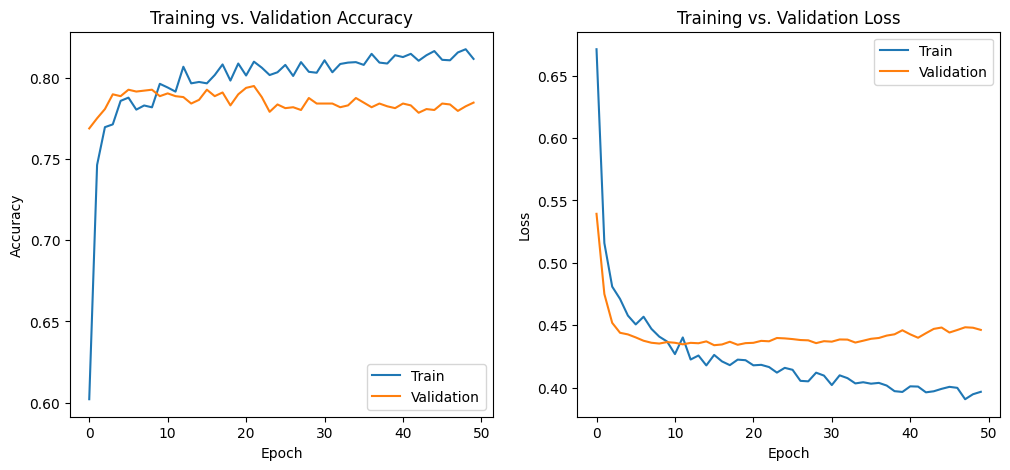

In [ ]:
updated_history_df = pd.DataFrame(updated_history.history)
plot_data(history_df)

In [ ]:
loss, accuracy = updated_model.evaluate(X_val, y_val)
print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7808 - loss: 0.4444
Validation Loss: 0.4444
Validation Accuracy: 0.7808


In [ ]:
y_pred = (updated_model.predict(X_test) > 0.5).astype("int32")

print("\n\n", confusion_matrix(y_test, y_pred))
print("\n\n", classification_report(y_test, y_pred))

56/56 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step


 [[1122  172]
 [ 211  256]]


               precision    recall  f1-score   support

       False       0.84      0.87      0.85      1294
        True       0.60      0.55      0.57       467

    accuracy                           0.78      1761
   macro avg       0.72      0.71      0.71      1761
weighted avg       0.78      0.78      0.78      1761



# Comparing Original to Updated Model

Comparing the two models, the newly tuned model is much stronger at detecting the True class. Originally, the model had a validation accuracy of 75.24% and struggled to detect Trues, with a 42% recall. Tuning the model with updated hyperparameters increased both accuracy and recall for True classes; recall for True has also increased to 65%, and validation accuracy to 77.88%, and the F1-score increased from 0.47 to 0.62.

The tuned model does seem a bit aggressive for the True class and has more false positives, but it also comes with the trade-off of a substantial reduction of the false negatives. Having an overall lower validation loss of 0.4574 compared to the original of 0.7039.

In conclusion, the tuned model’s performance is much better at detecting True churn cases and results in a more balanced and reliable classifier.

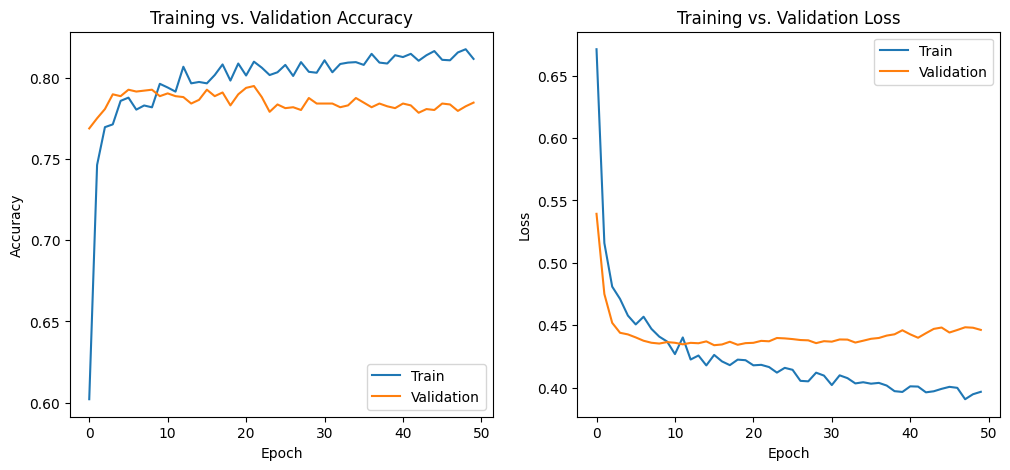

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7564 - loss: 0.7024


Validation Loss: 0.7024
Validation Accuracy: 0.7564


56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


 [[1066  228]
 [ 206  261]]


               precision    recall  f1-score   support

       False       0.84      0.82      0.83      1294
        True       0.53      0.56      0.55       467

    accuracy                           0.75      1761
   macro avg       0.69      0.69      0.69      1761
weighted avg       0.76      0.75      0.76      1761



In [ ]:
# Original Model
history_df = pd.DataFrame(history.history)
plot_data(history_df)

loss, accuracy = model.evaluate(X_val, y_val)
print(f"\n\nValidation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}\n\n")

y_pred = (model.predict(X_test) > 0.5).astype("int32")

print("\n\n", confusion_matrix(y_test, y_pred))
print("\n\n", classification_report(y_test, y_pred))

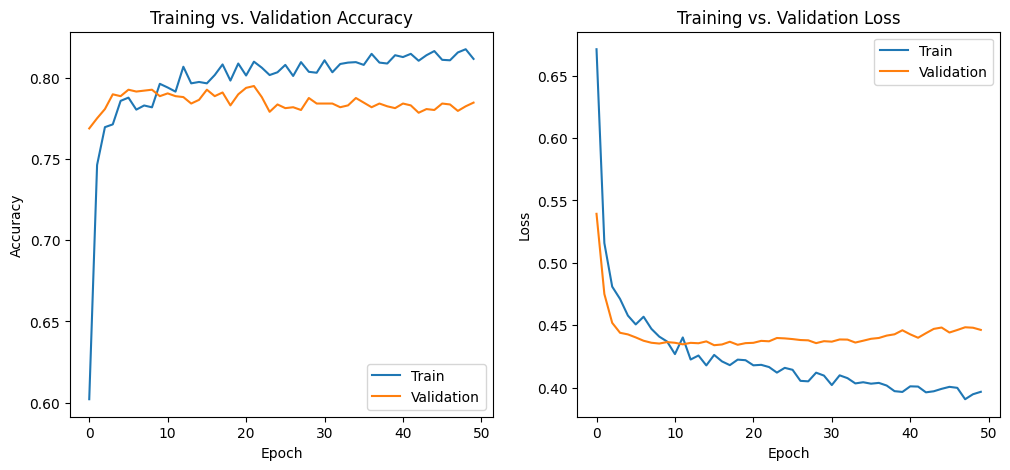

56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7808 - loss: 0.4444


Validation Loss: 0.4444
Validation Accuracy: 0.7808


56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


 [[1122  172]
 [ 211  256]]


               precision    recall  f1-score   support

       False       0.84      0.87      0.85      1294
        True       0.60      0.55      0.57       467

    accuracy                           0.78      1761
   macro avg       0.72      0.71      0.71      1761
weighted avg       0.78      0.78      0.78      1761



In [ ]:
# Updated Model
updated_history_df = pd.DataFrame(history.history)
plot_data(updated_history_df)

loss, accuracy = updated_model.evaluate(X_val, y_val)
print(f"\n\nValidation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy:.4f}\n\n")

y_pred = (updated_model.predict(X_test) > 0.5).astype("int32")

print("\n\n", confusion_matrix(y_test, y_pred))
print("\n\n", classification_report(y_test, y_pred))

# Business Interpretation of Churn Predictions

This Churn prediction model has a validation accuracy of 77.88% and can identify ~65% of customers with a high likelihood of churning. A model like this is useful for providing a target list of customers at risk of churn, reducing the need for a broad and costly campaign to identify them. Providing a useful tool for decision-making targeted towards minimizing customer churning.